# Aula 33: Introdução ao Matplotlib e simulações

Nas aulas anteriores, aprendemos a armazenar e calcular (NumPy) e a organizar dados em tabelas (Pandas). Agora vamos visualizar os dados!

Usaremos a biblioteca **Matplotlib**.

Objetivos da aula:
1. entender a estrutura de uma figura (`Figure` e `Axes`);
2. construir gráficos de linha, dispersão, histogramas e boxplots;
3. combinar vários gráficos numa mesma figura e integrar com o Pandas.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt   # por convenção, o módulo pyplot recebe o apelido plt

## 1. Figure e Axes

Em Matplotlib, há 2 objetos principais:

- **`Figure`** (`fig`): a tela inteira (controla tamanho, resolução, título geral...).
- **`Axes`** (`ax`): a área onde os dados são desenhados, com seus eixos (x e y), título, rótulos, legenda, etc. Uma figura pode ter vários `Axes`.

Costuma-se criar os dois de uma só vez com `plt.subplots()` e depois chamar métodos do `ax`: `ax.plot(...)`, `ax.set_title(...)`.

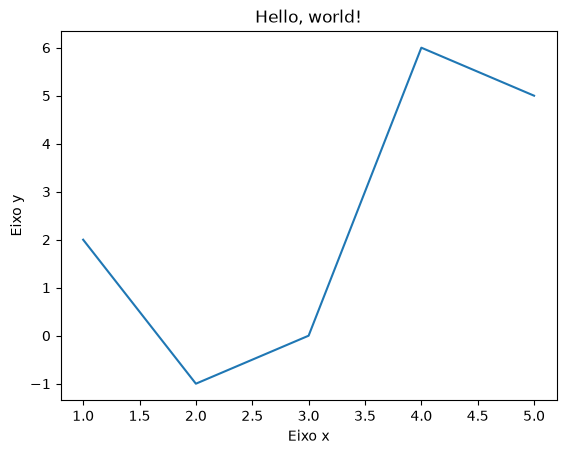

In [3]:
x = [1, 2, 3, 4, 5]
y = [2, -1, 0, 6, 5]

fig, ax = plt.subplots()   # cria uma Figure com um único Axes
ax.plot(x, y)              # desenha uma linha ligando os pontos (x, y)
ax.set_title("Hello, world!")
ax.set_xlabel("Eixo x")
ax.set_ylabel("Eixo y")
plt.show() # Exibe a figura (opcional em notebooks)

`plt.show()` manda exibir a figura. Em um notebook como este (Colab ou Jupyter), a figura é exibida na saída da célula mesmo sem esse comando, mas em scripts `.py` é necessário.

Controlamos o tamanho da figura com `figsize=(largura, altura)`:

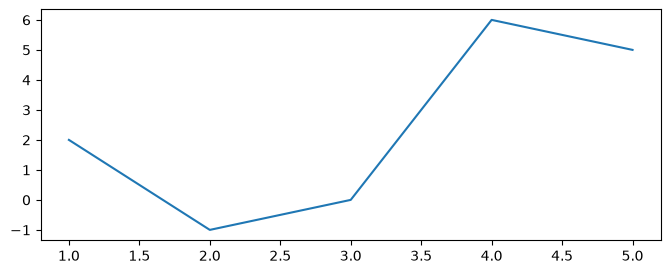

In [4]:
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(x, y)
plt.show()

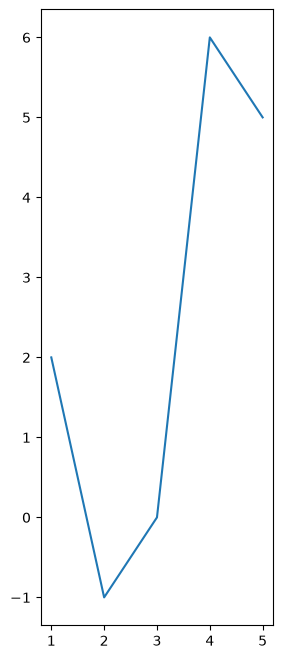

In [5]:
fig, ax = plt.subplots(figsize=(3, 8))
ax.plot(x, y)
plt.show()

> Você pode encontrar tutoriais usando `plt.plot(x, y)` em vez de `ax.plot(x, y)` a partir de um objeto `ax`:


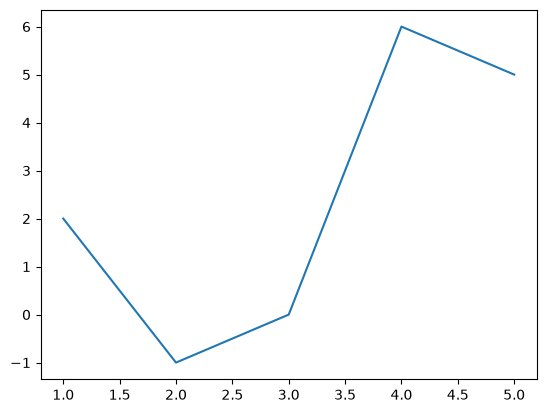

In [6]:
plt.plot(x, y) # uma só linha que faz a mesma coisa: Figure e Axes ficam IMPLÍCITOS!

Só que assim fica difícil controlar desenhos em vários gráficos ao mesmo tempo (...é similar a usar variável globais ou o gerador rng implícito do numpy).

Vamos manter o padrão de usar `fig, ax = plt.subplots()` e chamar os métodos no Axes `ax`.

O passo a passo de qualquer desenho é

1. criar Figure e Axes: `fig, ax = plt.subplots()`;
2. desenhar com `ax.plot` (linhas), `ax.scatter` (pontos), `ax.hist` (histograma), `ax.boxplot` (boxplot), e muitos outros...;
3. rotular com `ax.set_title` (título), `ax.set_xlabel` (rótulo do eixo x), `ax.set_ylabel` (rótulo do eixo y), `ax.legend` (legenda), ...;
4. `plt.show()`.

## 2. Gráficos de linha

O gráfico de linha liga pontos consecutivos. Use apenas quando a ordem dos pontos importa!

### Plotando funções

Usamos `np.linspace` (aula 31) para criar uma sequência de valores de $x$ igualmente espaçados.

In [7]:
x = np.linspace(0, 2 * np.pi, 200)   # 200 pontos de 0 a 2pi
print(x.shape)

(200,)


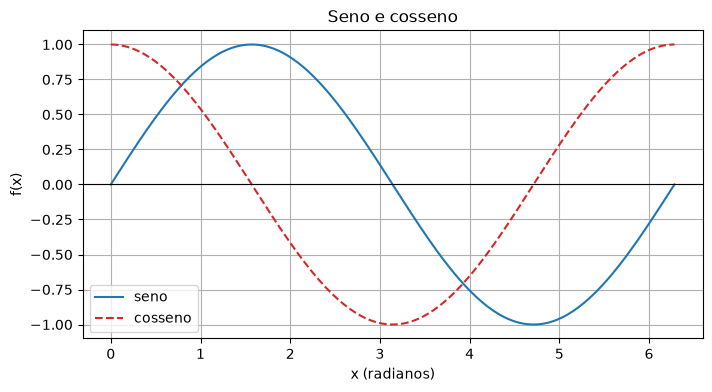

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(x, np.sin(x), label="seno", linestyle="-", color="tab:blue") # linhas
ax.plot(x, np.cos(x), label="cosseno", linestyle="--", color="tab:red") # linhas
ax.axhline(0, color="black", linewidth=0.8)   # linha horizontal de referência em y = 0
ax.set_title("Seno e cosseno")
ax.set_xlabel("x (radianos)")
ax.set_ylabel("f(x)")
ax.legend()      # mostra a legenda com os textos em ax.plot(..., label="esse texto aqui")
ax.grid(True)    # grade de fundo
plt.show()

### Personalizando a aparência

Os principais argumentos de `ax.plot`:

| Argumento | Exemplos | Efeito | Documentação
|---|---|---|---|
| `color` | `"red"`, `"tab:blue"`, `"#1f77b4"` | cor da linha  | https://matplotlib.org/stable/users/explain/colors/colors.html |
| `linestyle` (ou `ls`) | `"-"`, `"--"`, `":"`, `"-."` | tipo de traço | https://matplotlib.org/stable/gallery/lines_bars_and_markers/linestyles.html |
| `linewidth` (ou `lw`) | `1`, `2.5` | espessura |
| `marker` | `"o"`, `"s"`, `"^"`, `"x"` | marcador em cada ponto | https://matplotlib.org/stable/api/markers_api.html#module-matplotlib.markers |
| `label` | `"Grupo A"` | nome na legenda |
| `alpha` | `0.3` | transparência (0 = invisível, 1 = opaco) |

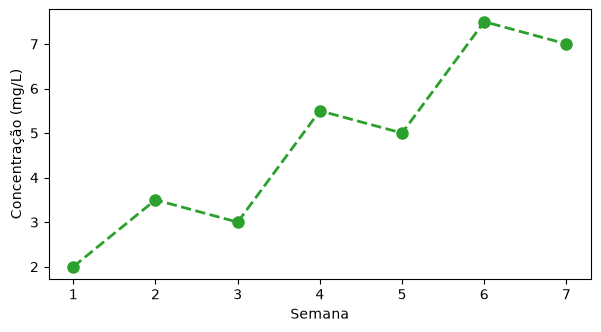

In [9]:
x = np.arange(1, 8) # [1, 2, 3, 4, 5, 6, 7]
y = np.array([2.0, 3.5, 3.0, 5.5, 5.0, 7.5, 7.0])

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(x, y, marker="o", linestyle="--", color="tab:green", linewidth=2, markersize=8)
ax.set_xlabel("Semana")
ax.set_ylabel("Concentração (mg/L)")
plt.show()

### Exemplo: jogo de azar

Um jogador faz apostas sucessivas em um jogo, começando com um saldo de 100 reais: a cada rodada, o jogador aposta metade de seu saldo atual; o jogador ganha o dobro do valor apostado (com 20% de chance) ou ele perde tudo apostado (80% de chance). O saldo acumulado após $t$ apostas é uma variável aleatória. Qual seu valor esperado? (vamos testar com simulação)

- `rng.choice([2, 0], size=1, p=[0.2, 0.8])` sorteia o multiplicador (2 = dobra valor apostado, 0 = perde valor apostado) com as probabilidades 20% e 80% respectivamente.


Média amostral: 14.375


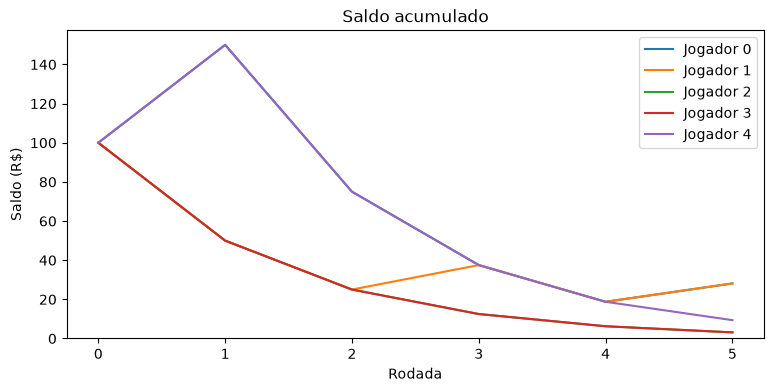

In [10]:
rng = np.random.default_rng(seed=3)
NUM_RODADAS = 5
NUM_JOGADORES = 5

fig, ax = plt.subplots(figsize=(9, 4))
saldo_apos_rodadas = []
for jogador in range(NUM_JOGADORES):
    saldo_atual = 100
    saldos = [saldo_atual]
    multiplicador = rng.choice([2, 0], size=NUM_RODADAS, p=[0.2, 0.8])
    for i in range(NUM_RODADAS):
        valor_apostado = saldo_atual / 2
        saldo_atual = (saldo_atual - valor_apostado) + valor_apostado * multiplicador[i]
        saldos.append(saldo_atual)
    ax.plot(saldos, label=f'Jogador {jogador}')
    saldo_apos_rodadas.append(saldo_atual)

print('Média amostral:', np.mean(saldo_apos_rodadas))

ax.set_title("Saldo acumulado")
ax.set_xlabel("Rodada")
ax.set_ylabel("Saldo (R$)")
ax.set_ylim(bottom=0) # força mostrar y = 0
if NUM_JOGADORES <= 10:
    ax.legend()
plt.show()

Versão vetorizada (mais rápida)

In [11]:
rng = np.random.default_rng(seed=3)
NUM_RODADAS = 5
NUM_JOGADORES = 5
SALDO_INICIAL = 100

# Seja S o saldo atual.
# Em caso de vitória, o novo saldo será (S / 2) + 2 * (S / 2) = 1.5S
# Em caso de derrota, o novo saldo será (S / 2) + 0 * (S / 2) = 0.5S
multiplicador = rng.choice([1.5, 0.5], size=(NUM_JOGADORES, NUM_RODADAS), p=[0.2, 0.8])
# 1.5, 0.5, 1.5, 1.5, 0.5 (Jogador 1) <- multiplicador de cada rodada
# 0.5, 0.5, 0.5, 0.5, 0.5 (Jogador 2; azarado)
multiplicador = np.cumprod(multiplicador, axis=1)
# 1.5, 0.75, 1.125, 1.6875, 0.84375 (Jogador 1) <- multiplicador a partir da 0ª rodada
# 0.5, 0.25, 0.125, 0.0625, 0.03125 (Jogador 2) <- multiplicador a partir da 0ª rodada
saldos = SALDO_INICIAL * multiplicador
coluna_de_100s = np.full(NUM_JOGADORES, SALDO_INICIAL) # shape: (NUM_JOGADORES,)
saldos = np.c_[coluna_de_100s, saldos] # Junta as colunas em sequência
print(saldos)

[[100.    150.     75.     37.5    18.75   28.125]
 [100.     50.     25.     37.5    18.75   28.125]
 [100.     50.     25.     12.5     6.25    3.125]
 [100.     50.     25.     12.5     6.25    3.125]
 [100.    150.     75.     37.5    18.75    9.375]]


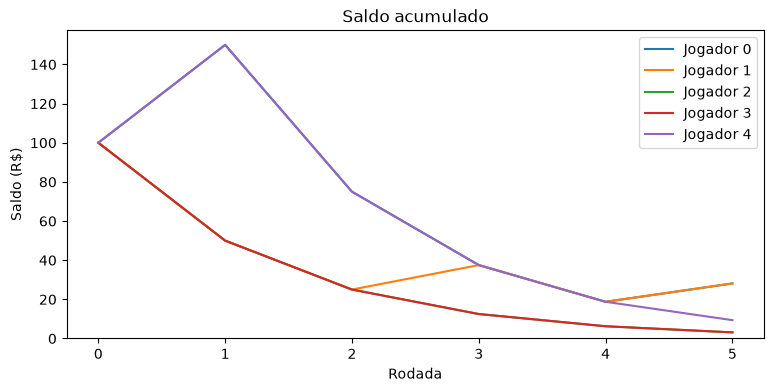

In [12]:
fig, ax = plt.subplots(figsize=(9, 4))
for i in range(NUM_JOGADORES):
    ax.plot(saldos[i], label=f'Jogador {i}')
ax.set_title("Saldo acumulado")
ax.set_xlabel("Rodada")
ax.set_ylabel("Saldo (R$)")
ax.legend()
ax.set_ylim(bottom=0) # força mostrar y = 0
plt.show()

## 3. Gráficos de dispersão (scatterplot)

O gráfico de dispersão desenha um ponto (2D) por observação. Serve para investigar se (e como) duas variáveis se relacionam. Diferente do gráfico de linha, os pontos **não** são ligados, e a ordem não importa.

### Gerando dados: altura e peso

Vamos simular 200 pessoas. O sexo é sorteado; a altura depende do sexo (distribuições normais com médias diferentes); e o peso depende linearmente da altura, mais um ruído aleatório:

$$\text{peso} = -60 + 0.75 \cdot \text{altura} + \varepsilon, \qquad \varepsilon \sim \mathcal N(0,\, 6^2)$$

In [13]:
rng = np.random.default_rng(seed=2)
n = 200

sexo = rng.choice(["F", "M"], size=n)
# np.where(condição, valor_se_verdadeiro, valor_se_falso) escolhe, posição a posição, entre dois arrays (é um "if" vetorizado).
altura = np.where(sexo == "M", rng.normal(176, 7, n), rng.normal(163, 6, n))
eps = rng.normal(0, 6, n)
peso = -60 + 0.75 * altura + eps

print(altura[:5].round(1))
print(peso[:5].round(1))
print(sexo[:5])

[171.3 167.6 172.5 166.6 166. ]
[54.  59.  70.4 62.8 59.3]
['M' 'F' 'F' 'F' 'F']


Agora o scatter. O argumento `alpha` deixa os pontos semitransparentes, o que ajuda a enxergar regiões onde eles se sobrepõem.

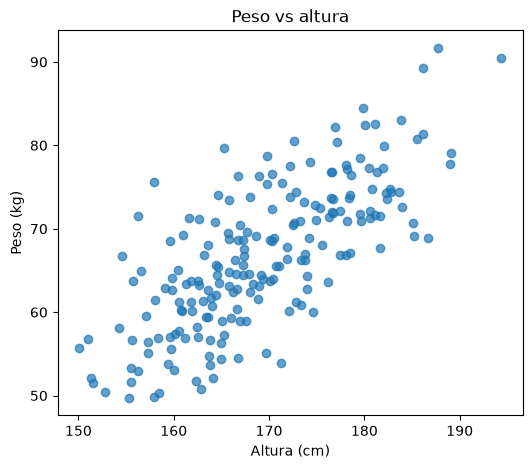

In [14]:
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(altura, peso, alpha=0.7)
ax.set_title("Peso vs altura")
ax.set_xlabel("Altura (cm)")
ax.set_ylabel("Peso (kg)")
plt.show()

### Colorindo por grupo

Para distinguir os grupos, filtramos os dados com **máscaras booleanas** (aula 31) e chamamos `ax.scatter` uma vez por grupo, cada um com seu `label`.

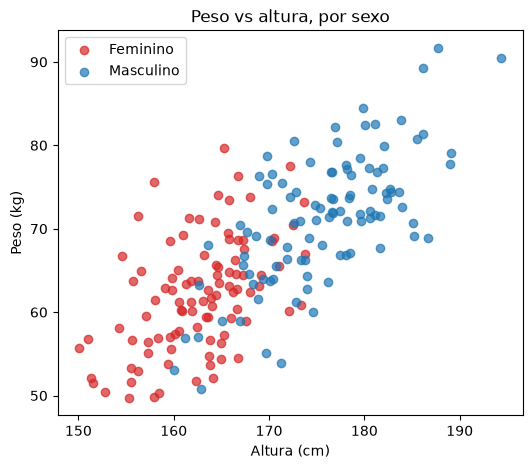

In [15]:
mask_F = (sexo == "F")
mask_M = (sexo == "M")

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(altura[mask_F], peso[mask_F], alpha=0.7, label="Feminino", color="tab:red")
ax.scatter(altura[mask_M], peso[mask_M], alpha=0.7, label="Masculino", color="tab:blue")
ax.set_title("Peso vs altura, por sexo")
ax.set_xlabel("Altura (cm)")
ax.set_ylabel("Peso (kg)")
ax.legend()
plt.show()

### Rete ajustada (minimizar erro quadrático)


`np.polyfit(x, y, deg=1)` ajusta a reta que minimiza os erros quadráticos e devolve `[a, b]` da equação de reta $y = ax + b$.

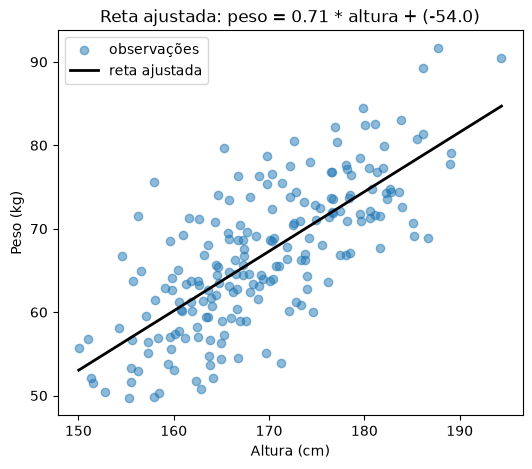

In [16]:
a, b = np.polyfit(altura, peso, deg=1)
x = np.array([altura.min(), altura.max()]) # para desenhar uma reta, basta 2 pontos
y = a * x + b

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(altura, peso, alpha=0.5, label="observações")
ax.plot(x, y, color="black", linewidth=2, label="reta ajustada")
ax.set_title(f"Reta ajustada: peso = {a:.2f} * altura + ({b:.1f})")
ax.set_xlabel("Altura (cm)")
ax.set_ylabel("Peso (kg)")
ax.legend()
plt.show()

## 4. Histogramas

O histograma mostra a distribuição de uma variável numérica. Dividimos a faixa de valores em intervalos consecutivos (os *bins*) e contamos quantas observações caem em cada um; a altura de cada barra representa essa contagem.

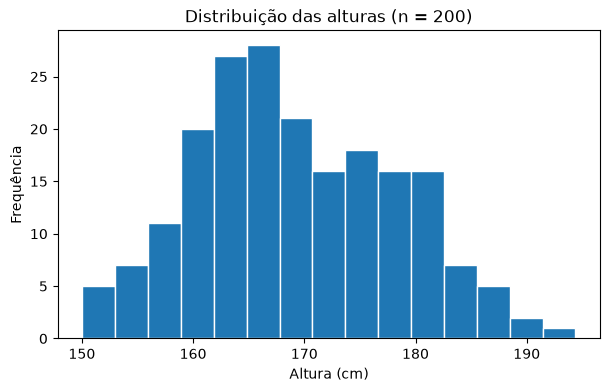

In [17]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(altura, bins=15, edgecolor="white")
ax.set_title("Distribuição das alturas (n = 200)")
ax.set_xlabel("Altura (cm)")
ax.set_ylabel("Frequência")
plt.show()

`np.histogram` faz a contagem sem desenhar. `ax.hist` é essencialmente `np.histogram` + desenho de barras.

In [18]:
contagens, limites = np.histogram(altura, bins=15)
print("Frequência absoluta por bin:", contagens)
print("Frequencia relativa (%) por bin:", contagens / contagens.sum() * 100)
print("Limites dos bins:", limites.round(1))

Frequência absoluta por bin: [ 5  7 11 20 27 28 21 16 18 16 16  7  5  2  1]
Frequencia relativa (%) por bin: [ 2.5  3.5  5.5 10.  13.5 14.  10.5  8.   9.   8.   8.   3.5  2.5  1.
  0.5]
Limites dos bins: [150.  153.  155.9 158.9 161.9 164.8 167.8 170.7 173.7 176.6 179.6 182.6
 185.5 188.5 191.4 194.4]


### Criando vários gráficos em uma mesma Figure

Vamos criar vários gráficos (Axes) na mesma Figure, para ver o efeito dos bins nos histogramas.

Poucos bins escondem a forma da distribuição; bins demais deixam o gráfico "serrilhado", dominado por ruído amostral:

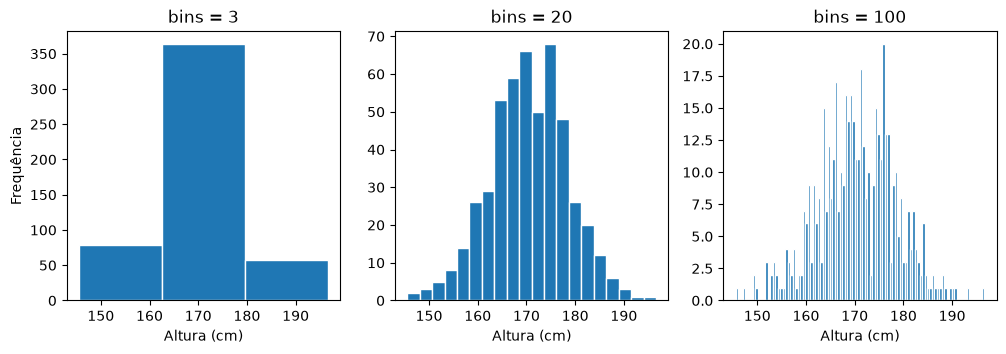

In [19]:
NUMERO_DE_LINHAS = 1
NUMERO_DE_COLUNAS = 3
# Temos 3 Axes associadas ao mesmo Figure: axs[0], axs[1], axs[2]
fig, axs = plt.subplots(NUMERO_DE_LINHAS, NUMERO_DE_COLUNAS, figsize=(12, 3.5))

rng = np.random.default_rng(seed=3)
amostra = rng.normal(loc=170, scale=8, size=500) # média 170, desvio padrão 8

N_BINS = [3, 20, 100]
for i in range(len(N_BINS)):
    ax = axs[i]
    n_bins = N_BINS[i]
    ax.hist(amostra, bins=n_bins, edgecolor="white")
    ax.set_title(f"bins = {n_bins}")
    ax.set_xlabel("Altura (cm)")
axs[0].set_ylabel("Frequência") # label do eixo y apenas no mais à esquerda
plt.show()

### Frequência vs densidade

Com `density=True`, a altura das barras é ajustada para que a área total do histograma seja 1. Assim, o histograma passa a ser comparável a uma função densidade de probabilidade. A densidade da normal $\mathcal N(\mu, \sigma^2)$ é

$$f(x) = \frac{1}{\sigma\sqrt{2\pi}}\, e^{-\frac{(x-\mu)^2}{2\sigma^2}}$$

Vamos sobrepor essa curva ao histograma de uma amostra simulada. Quanto maior a amostra, melhor o encaixe.

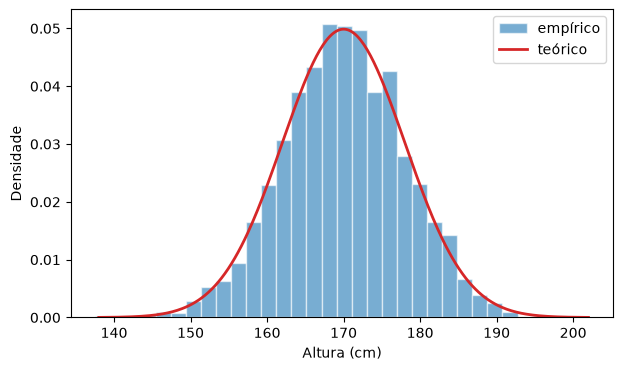

In [20]:
rng = np.random.default_rng(seed=4)
mu = 170
sigma = 8
amostra = rng.normal(mu, sigma, size=2000)

esquerda = mu - 4 * sigma
direita = mu + 4 * sigma
x = np.linspace(esquerda, direita, 300)
densidade = (1 / (sigma * np.sqrt(2 * np.pi))) * np.exp(-(x - mu) ** 2 / (2 * sigma ** 2))

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(amostra, bins=30, density=True, alpha=0.6, edgecolor="white", label="empírico")
ax.plot(x, densidade, color="tab:red", linewidth=2, label="teórico")
ax.set_xlabel("Altura (cm)")
ax.set_ylabel("Densidade")
ax.legend()
plt.show()

### Distribuição exponencial

Tempos de espera e tempos até falha costumam ser modelados pela distribuição exponencial.

Com `ax.axvline(x)` desenhamos uma linha vertical, que pode marcar a média ou a mediana.

Média: 4.75   Mediana: 3.35


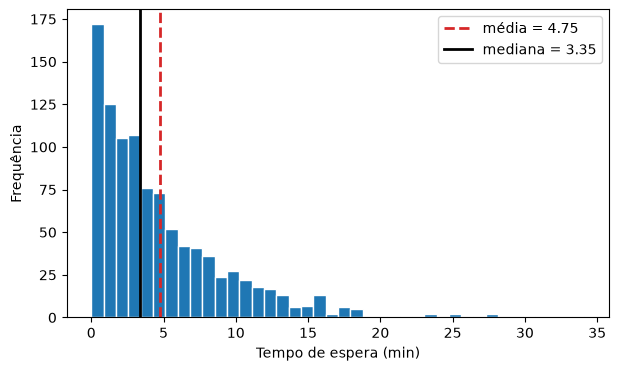

In [21]:
rng = np.random.default_rng(seed=5)
tempos = rng.exponential(scale=5.0, size=1000)

media = tempos.mean()
mediana = np.median(tempos)
print(f"Média: {media:.2f}   Mediana: {mediana:.2f}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(tempos, bins=40, edgecolor="white")
ax.axvline(media, color="tab:red", linestyle="--", linewidth=2, label=f"média = {media:.2f}")
ax.axvline(mediana, color="black", linestyle="-", linewidth=2, label=f"mediana = {mediana:.2f}")
ax.set_xlabel("Tempo de espera (min)")
ax.set_ylabel("Frequência")
ax.legend()
plt.show()

A densidade da [Distribuição exponencial](https://pt.wikipedia.org/wiki/Distribui%C3%A7%C3%A3o_exponencial) é dada por

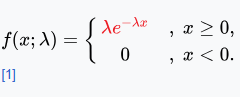

em que $\lambda > 0$ é um parâmetro da distribuição.

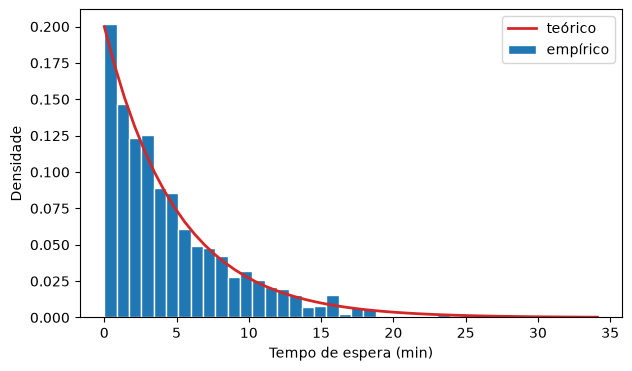

In [22]:
x = np.linspace(0, tempos.max())
rate = 1 / 5 # a função rng.exponencial recebe o inverso do rate
densidade = rate * np.exp(-rate * x)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(x, densidade, color="tab:red", linewidth=2, label="teórico")
ax.hist(tempos, bins=40, density=True, edgecolor="white", label="empírico")
ax.set_xlabel("Tempo de espera (min)")
ax.set_ylabel("Densidade")
ax.legend()
plt.show()

### Histogramas sobrepostos

Para comparar a altura de F e M, desenhamos os dois histogramas no mesmo `Axes`, com `alpha < 1` (transparência) e os mesmos bins (para a comparação ser justa) e `density=True` (para comparar formas mesmo com tamanhos de grupo diferentes).

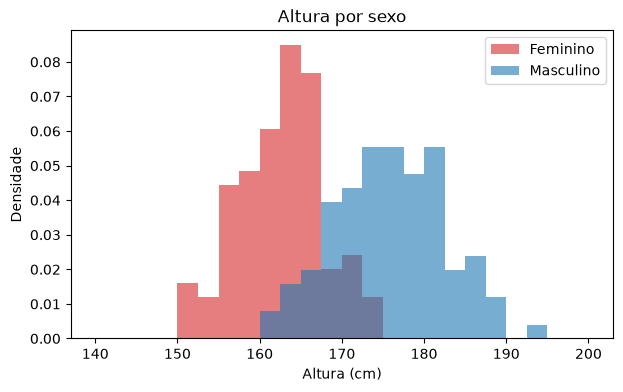

In [23]:
bins = np.linspace(140, 200, 25)   # bordas comuns aos dois grupos

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(altura[mask_F], bins=bins, alpha=0.6, density=True, label="Feminino", color="tab:red")
ax.hist(altura[mask_M], bins=bins, alpha=0.6, density=True, label="Masculino", color="tab:blue")
ax.set_xlabel("Altura (cm)")
ax.set_ylabel("Densidade")
ax.set_title("Altura por sexo")
ax.legend()
plt.show()

Compare este gráfico com o primeiro histograma desta seção, que misturava todo mundo!

Veremos a seguir outra maneira de comparar distribuições: boxplots!

## 5. Boxplots (diagramas de caixa)


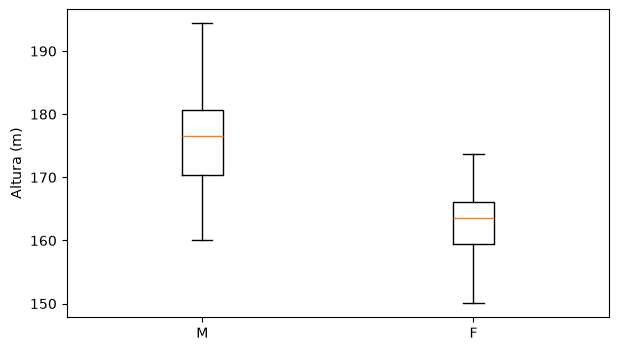

In [24]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.boxplot([altura[mask_M], altura[mask_F]], tick_labels=['M', 'F'])
ax.set_ylabel('Altura (m)')
plt.show()

O boxplot resume uma distribuição em 5 números e destaca valores atípicos (*outliers*):

- a caixa vai do 1º quartil $Q_1$ ao 3º quartil $Q_3$ (contém os 50% centrais dos dados); sua altura é a amplitude interquartil $\text{IQR} = Q_3 - Q_1$;
- a linha dentro da caixa é a mediana;
- os bigodes (*whiskers*) se estendem até o dado mais extremo que ainda esteja dentro de $[Q_1 - 1.5\,\text{IQR},\; Q_3 + 1.5\,\text{IQR}]$;
- pontos fora desse intervalo são desenhados individualmente e considerados outliers (valores atípicos).

### Exemplo: tempo de reação em um experimento

Três grupos: controle e dois tratamentos (A e B). Tempo de reação em milissegundos.

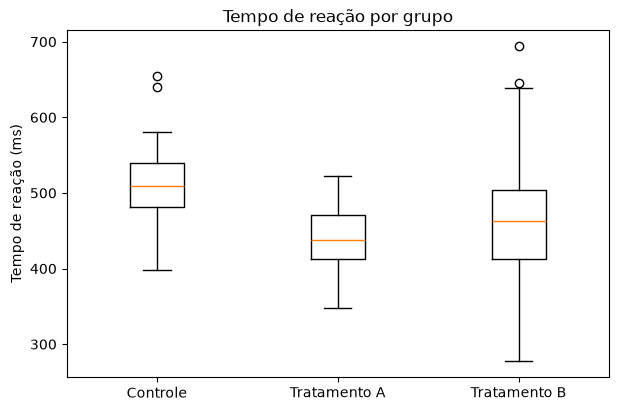

In [25]:
rng = np.random.default_rng(seed=6)

controle = rng.normal(500, 40, size=60)
controle = np.append(controle, [640, 655])    # inserimos dois valores atípicos "à mão"
trat_a = rng.normal(450, 40, size=60)         # mais rápido, mesma variabilidade
trat_b = rng.normal(450, 80, size=60)         # mais rápido em média, mas mais variável

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.boxplot([controle, trat_a, trat_b], tick_labels=["Controle", "Tratamento A", "Tratamento B"])
ax.set_ylabel("Tempo de reação (ms)")
ax.set_title("Tempo de reação por grupo")
plt.show()

> *(Em versões do Matplotlib anteriores à 3.9, o parâmetro `tick_labels` chama-se `labels`)*

Podemos calcular com o numpy os elementos da caixa do grupo controle, com `np.percentile`:

In [26]:
q1, mediana, q3 = np.percentile(controle, [25, 50, 75])
iqr = q3 - q1
lim_inf = q1 - 1.5 * iqr
lim_sup = q3 + 1.5 * iqr

print(f"Q1 = {q1:.1f} | mediana = {mediana:.1f} | Q3 = {q3:.1f} | IQR = {iqr:.1f}")
print(f"Intervalo dos bigodes: [{lim_inf:.1f}, {lim_sup:.1f}]")

outliers = controle[(controle < lim_inf) | (controle > lim_sup)] # parênteses obrigatórios, por conta da precedência de operadores
print("Outliers detectados:", outliers)

Q1 = 482.0 | mediana = 509.8 | Q3 = 539.4 | IQR = 57.4
Intervalo dos bigodes: [395.9, 625.4]
Outliers detectados: [640. 655.]


A partir desses números, podemos usar `ax.bxp` para plotar (um ou mais) boxplots manualmente.

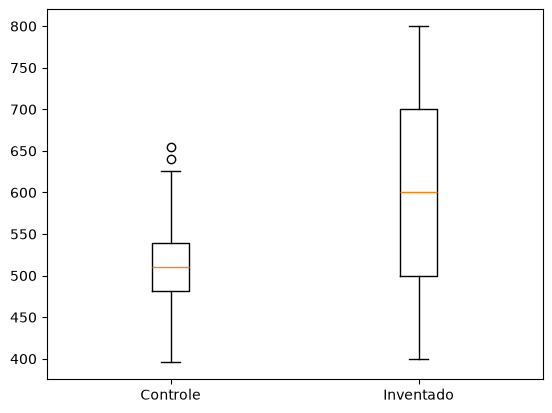

In [27]:
fig, ax = plt.subplots()
boxplot_stats_1 = {
    'med': mediana,
    'q1': q1,
    'q3': q3,
    'whislo': lim_inf, # whiskers low (bigode baixo)
    'whishi': lim_sup, # whiskers high (bigode alto)
    'fliers': outliers # voadores (pontos soltos)
}
boxplot_stats_2 = {
    # valores inventados
    'med': 600,
    'q1': 500,
    'q3': 700,
    'whislo': 400, # whiskers low (bigode baixo)
    'whishi': 800, # whiskers high (bigode alto)
    'fliers': []   # voadores (pontos soltos)
}
ax.bxp([boxplot_stats_1, boxplot_stats_2]) # lista de informações de boxplots...
ax.set_xticklabels(['Controle', 'Inventado'])
plt.show()

Por padrão, o boxplot marca a mediana. Com `showmeans=True` ele também marca a média (triângulo verde).

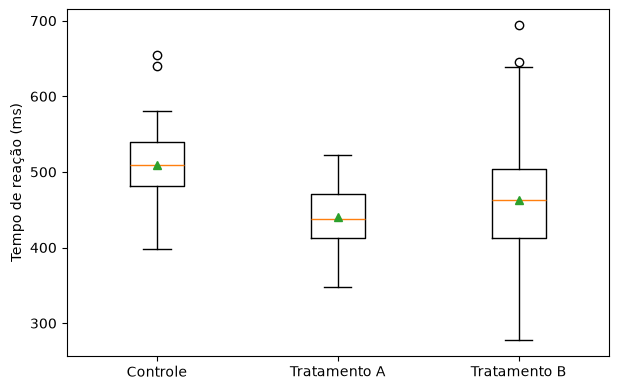

In [28]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.boxplot([controle, trat_a, trat_b], tick_labels=["Controle", "Tratamento A", "Tratamento B"], showmeans=True)
ax.set_ylabel("Tempo de reação (ms)")
plt.show()

Veja o histograma e o boxplot de uma amostra da distribuição exponencial:

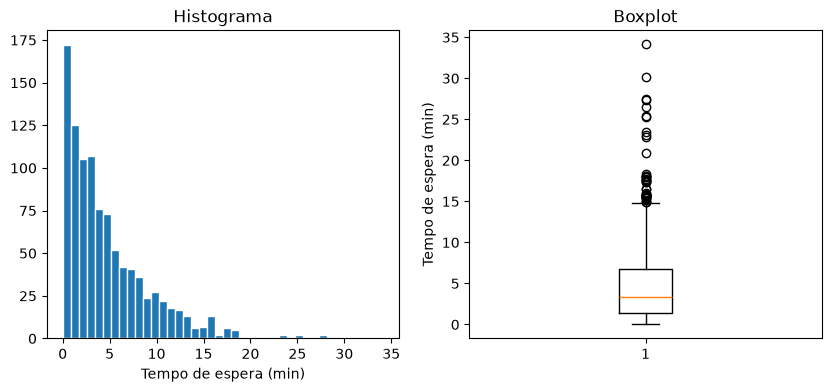

In [29]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4))

axs[0].hist(tempos, bins=40, edgecolor="white")
axs[0].set_title("Histograma")
axs[0].set_xlabel("Tempo de espera (min)")

axs[1].boxplot(tempos)
axs[1].set_title("Boxplot")
axs[1].set_ylabel("Tempo de espera (min)")

plt.show()

## 6. Gráfico de barras (para variáveis categóricas)

Histogramas são para variáveis numéricas contínuas. Para categorias (tipo sanguíneo, grupo, curso...), usamos o gráfico de barras: `ax.bar(categorias, alturas)`.

In [30]:
rng = np.random.default_rng(seed=7)

tipos = np.array(["O", "A", "B", "AB"])
pesos = [0.45, 0.40, 0.12, 0.03]
amostra_sangue = rng.choice(tipos, size=500, p=pesos)
print(amostra_sangue.shape)

# return_counts=True nos dá a frequência de cada tipo sanguíneo na amostra
categorias, contagens = np.unique(amostra_sangue, return_counts=True)
print(categorias, contagens)

(500,)
['A' 'AB' 'B' 'O'] [212  11  62 215]


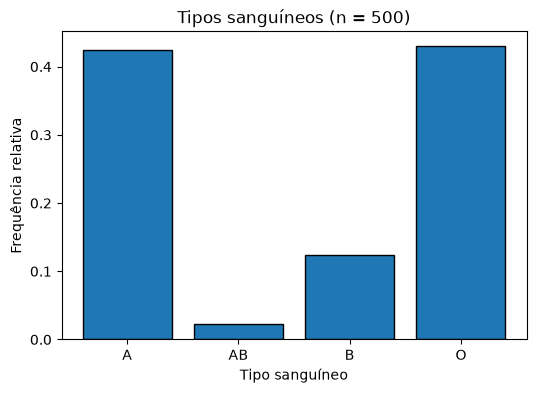

In [31]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(categorias, contagens / contagens.sum(), edgecolor="black")
ax.set_xlabel("Tipo sanguíneo")
ax.set_ylabel("Frequência relativa")
ax.set_title("Tipos sanguíneos (n = 500)")
plt.show()

## 7. Vários gráficos na mesma figura

`plt.subplots(linhas, colunas)` cria uma grade de `Axes`. O retorno `axs` é um array NumPy (de 1 ou 2 dimensões) com os `Axes`; `axs.flat` permite percorrê-los num único laço `for`.

Recomendações:
- `layout="constrained"` ajusta os espaçamentos automaticamente para que títulos e rótulos não se sobreponham;
- `sharex=True` / `sharey=True` fazem os gráficos compartilharem a mesma escala, útil para comparações!
- `fig.suptitle(...)` coloca um título geral.

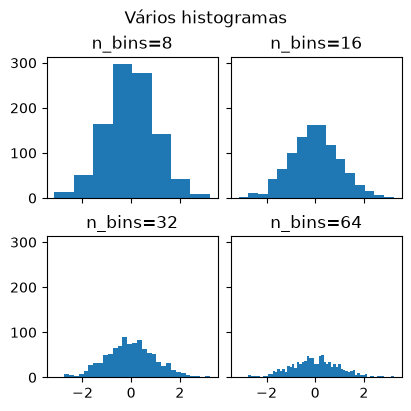

In [32]:
rng = np.random.default_rng(seed=8)
x = rng.normal(0, 1, size=1000)

fig, axs = plt.subplots(2, 2, figsize=(4, 4), layout="constrained", sharex=True, sharey=True)
axs = axs.flat # em vez de matriz 2D, deixa em axs um vetor 1D dos Axes
N_BINS = [8, 16, 32, 64]
for i in range(len(axs)):
    ax = axs[i]
    n_bins = N_BINS[i]
    ax.hist(x, bins=n_bins)
    ax.set_title(f"n_bins={n_bins}")
fig.suptitle("Vários histogramas")
plt.show()

### Salvando a figura em arquivo

`fig.savefig("nome.png", dpi=150)` grava a figura. Formatos comuns: `.png`, `.pdf`, `.svg`. No Colab, o arquivo aparece no painel lateral de arquivos e pode ser baixado de lá.

In [33]:
fig.savefig("histogramas.png", dpi=150)
print("Figura salva como histogramas.png")

Figura salva como histogramas.png


## 8. Integração com o Pandas

`Series` e `DataFrame` têm métodos de gráficos que usam o Matplotlib por baixo e já aproveitam os nomes das colunas para rotular os eixos. Eles devolvem o `Axes`, então podemos continuar personalizando.

Vamos montar um `DataFrame` com os dados de altura e peso simulados na seção 3.

In [34]:
df = pd.DataFrame({"sexo": sexo, "altura": altura, "peso": peso})
df.head()

,sexo,altura,peso
0,M,171.254797,53.961996
1,F,167.573011,58.951035
2,F,172.496834,70.426160
3,F,166.623946,62.782994
4,F,165.989685,59.304997


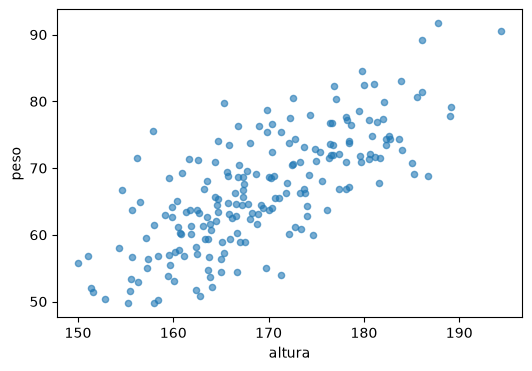

In [35]:
# Dispersão: colunas x e y indicadas pelo nome
df.plot.scatter(x="altura", y="peso", alpha=0.6, figsize=(6, 4))
plt.show()

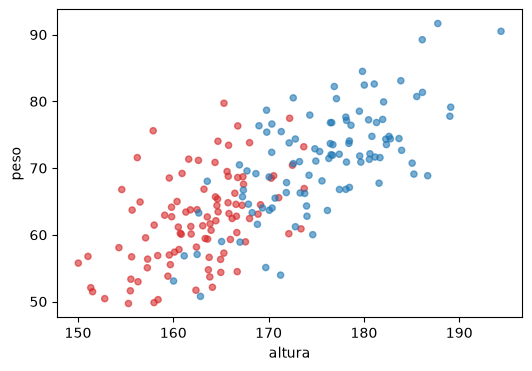

In [36]:
# Cores por grupo: mapeamos cada categoria para uma cor
cores = df["sexo"].map({"F": "tab:red", "M": "tab:blue"})
df.plot.scatter(x="altura", y="peso", c=cores, alpha=0.6, figsize=(6, 4))
plt.show()

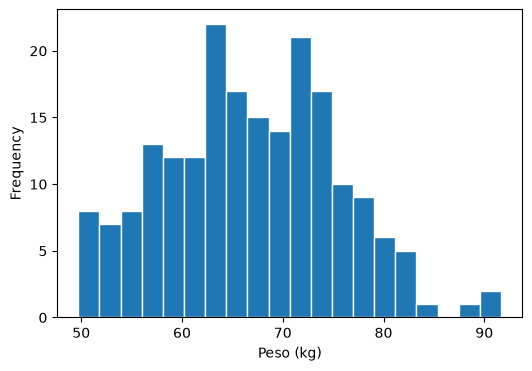

In [37]:
# Histograma de uma coluna (Series)
df["peso"].plot.hist(bins=20, edgecolor="white", figsize=(6, 4))
plt.xlabel("Peso (kg)")
plt.show()

`df.boxplot(column=..., by=...)` agrupa e desenha um boxplot por categoria.

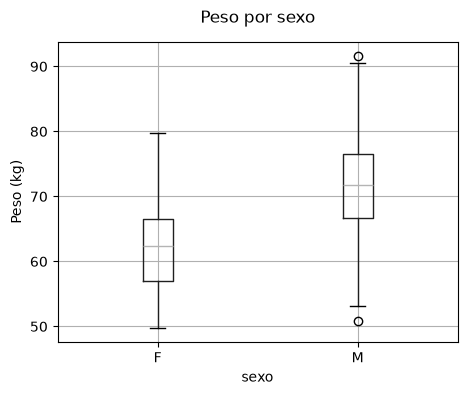

In [38]:
fig, ax = plt.subplots(figsize=(5, 4))
df.boxplot(column="peso", by="sexo", ax=ax)   # ax=ax: desenha dentro do Axes que criamos
ax.set_ylabel("Peso (kg)")
ax.set_title("")
fig.suptitle("Peso por sexo")
plt.show()

O argumento `ax=ax` é a "ponte" entre os dois mundos: permite criar a figura com Matplotlib e pedir ao Pandas que desenhe dentro dela.

## 9. Resumo

| Pergunta | Gráfico | Método |
|---|---|---|
| Como uma variável evolui na sequência/tempo? | Linha | `ax.plot` |
| Duas variáveis numéricas se relacionam? | Dispersão | `ax.scatter` |
| Qual a forma da distribuição de uma variável numérica? | Histograma | `ax.hist` |
| Como comparar a distribuição entre vários grupos? Há atípicos? | Boxplot | `ax.boxplot` |
| Quantas observações em cada categoria? | Barras | `ax.bar` |

## Exercício 1: histograma e boxplot

Retomando o cenário da aula 31: monitoramento da pressão arterial sistólica de 100 pacientes simulados em um estudo clínico.
* Média populacional: 125 mmHg.
* Desvio padrão: 15 mmHg.

Siga as instruções nas células de código.

Outliers: []


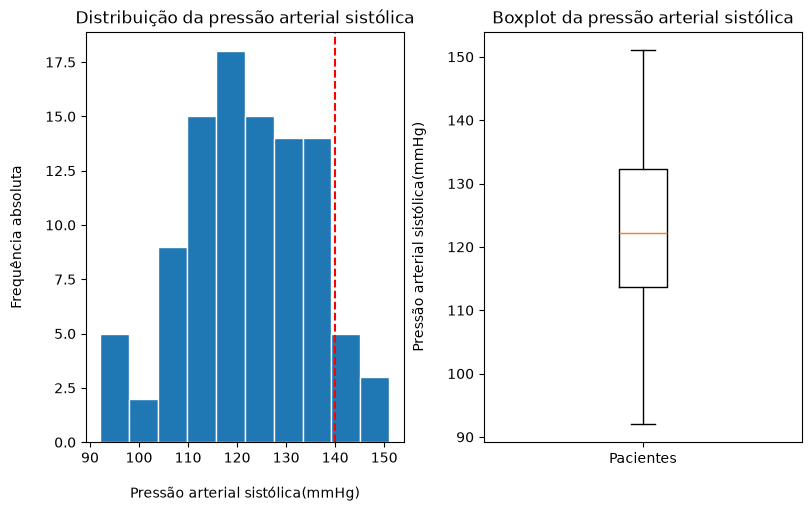

In [58]:
my_rng = np.random.default_rng(10)

# 1. Defina uma variável 'pressao' com 100 valores amostrados de uma normal de média 125 e desvio padrão 15
dist_pressao = my_rng.normal(125, 15, size=100)

fig, axs = plt.subplots(1, 2, figsize=(8,5), layout='constrained')
ax0 = axs[0]
ax0.hist(dist_pressao, bins=10, edgecolor='white')
ax0.axvline(140, color='red', linestyle='--')
ax0.set_title('Distribuição da pressão arterial sistólica')
ax0.set_xlabel('Pressão arterial sistólica(mmHg)', labelpad=15)
ax0.set_ylabel('Frequência absoluta', labelpad=15)

ax1=axs[1]
ax1.boxplot(dist_pressao)
ax1.set_title('Boxplot da pressão arterial sistólica')
ax1.set_ylabel('Pressão arterial sistólica(mmHg)', labelpad=15)
ax1.set_xticks([1], ['Pacientes'])

q1, med, q3 = np.percentile(dist_pressao, [25, 50, 75])
iqr = q3 - q1
lim_inf = q1 - 1.5 * iqr
lim_sup = q3 + 1.5 * iqr
outliers = dist_pressao[(dist_pressao < lim_inf) | (dist_pressao > lim_sup)]
print(f'Outliers: {outliers}')

plt.show()

# 2. Crie uma figura com 1 linha e 2 colunas de gráficos:
#    - à esquerda, o histograma da pressão (10 bins), com uma linha vertical vermelha tracejada em 140 mmHg (limiar de hipertensão);
#    - à direita, o boxplot da pressão.
#    Coloque títulos e rótulos de eixos (com unidade) nos dois.

O boxplot indicou algum outlier? Se sim, quais são os outliers? (Dica: calcule o intervalo $[Q_1 - 1.5\,\text{IQR},\; Q_3 + 1.5\,\text{IQR}]$ com `np.percentile`.)

## Exercício 2: dispersão e correlação

Num experimento, 80 pacientes recebem doses diferentes de um medicamento (de 0 a 10 mg). A resposta ao tratamento é modelada por

$$\text{resposta} = 2 + 1.5 \cdot \text{dose} + \varepsilon, \qquad \varepsilon \sim N(0, 2^2)$$

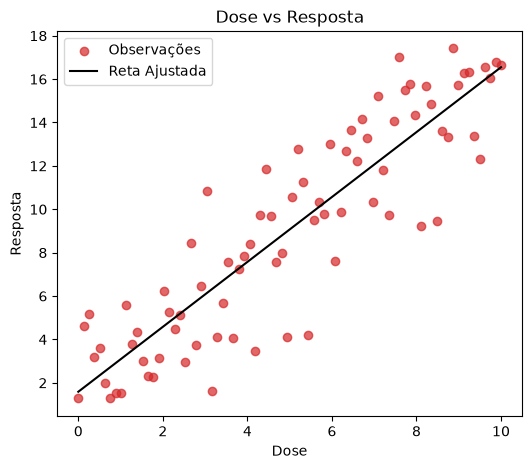

In [67]:
my_rng = np.random.default_rng(20)
N = 80

# 1. Sorteie 'dose': 80 valores de uma uniforme entre 0 e 10
dose = np.linspace(0, 10, N)

# 2. Calcule 'resposta' conforme a fórmula acima (ruído normal com média 0 e desvio padrão 2)
eps = my_rng.normal(0, 2, N)
resposta = 2 + 1.5 * dose + eps

# 3. Faça um gráfico de dispersão (dose no eixo x, resposta no eixo y) e desenhe por cima a reta ajustada com np.polyfit
_, ax = plt.subplots(figsize=(6, 5))
ax.scatter(dose, resposta, alpha=0.7, color='tab:red', label='Observações')
ax.set_title('Dose vs Resposta')
ax.set_xlabel('Dose')
ax.set_ylabel('Resposta')

a, b = np.polyfit(dose, resposta, deg=1)
x = np.array([dose.min(), dose.max()])
y = a * x + b

ax.plot(x, y, color='black', label='Reta Ajustada')

plt.legend()
plt.show()

## Exercício 3: simulação com dados

Simule 10000 lançamentos de dois dados justos e analise a soma dos dois.

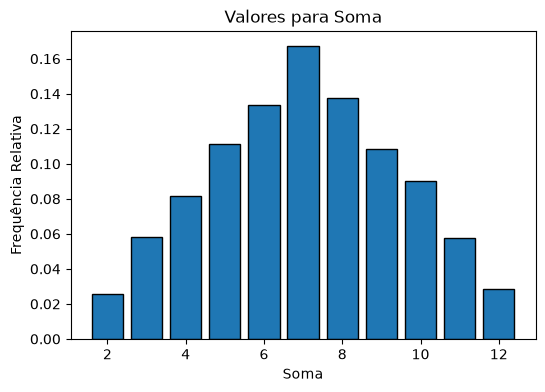

In [70]:
my_rng = np.random.default_rng(30)

# 1. Sorteie 'dado1' e 'dado2' (10000 valores inteiros de 1 a 6 cada; atenção ao limite superior de rng.integers!)
#    e defina 'soma = dado1 + dado2'
dado1 = my_rng.integers(1, 6, endpoint=True, size=10_000)
dado2 = my_rng.integers(1, 6, endpoint=True, size=10_000)
soma = dado1 + dado2

# 2. Calcule, na variável 'prop_sete', a proporção de lançamentos com soma igual a 7. O valor teórico é 1/6.
evento = soma[soma == 7]
pe = evento.size / soma.size

# 3. Faça um gráfico de barras com a frequência relativa de cada soma possível (2 a 12).
#    Dica: categorias, contagens = np.unique(soma, return_counts=True)
categorias, contagens = np.unique(soma, return_counts=True)
_, ax = plt.subplots(figsize=(6,4))
ax.bar(categorias, contagens / contagens.sum(), edgecolor='black')
ax.set_title('Valores para Soma')
ax.set_xlabel('Soma')
ax.set_ylabel('Frequência Relativa')
plt.show()
